# 03 - Baseline & Interpretable Tree Models
**L4 Group 23: Ismail Nooruddin, Munir Tariq, Ramsha Arshad**  
*CS/CE 351/363 - Artificial Intelligence, Fall 2026, Habib University*  
*Project Title: Classifying LIGO Glitches: Comparing CNNs and Simple Features*

---

### Objective & Research Motivation
In gravitational-wave astronomy, transient non-astrophysical noise artifacts ("glitches") severely contaminate detector strain data at LIGO Hanford ($H1$) and LIGO Livingston ($L1$). Before training computationally expensive Deep Convolutional Neural Networks (CNNs), it is scientifically essential to establish rigorous baselines and evaluate whether simple, interpretable feature-based machine learning models can achieve competitive classification performance.

In this notebook, we systematically evaluate four models:
1. **Baseline 1: Majority Class Classifier** (Heuristic lower-bound predicting the most frequent glitch class).
2. **Baseline 2: Raw-Pixel Decision Tree** (Trained directly on flattened $140 \times 170 = 23,800$ raw spectrogram pixels).
3. **Model 1: Feature-Based Decision Tree** (Trained on 34 physically motivated engineered features, tuned via validation Macro-F1).
4. **Model 2: Feature-Based Random Forest** (Ensemble of decision trees trained on 34 engineered features, tuned via validation Macro-F1).

All evaluations are conducted under our strict leak-free grouped split ($70\% / 15\% / 15\%$), ensuring that all four duration views of any unique glitch remain confined to a single partition.


In [1]:
# Step 3.1: Import necessary libraries and configure environment
import os
import sys
import json
import time
import joblib
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns

# Ensure src directory is accessible
sys.path.append(os.path.abspath('..'))
from src.models.baselines import MajorityClassBaseline, RawPixelDecisionTree
from src.models.tree_models import (
    ALL_FEATURE_COLS,
    prepare_feature_matrices,
    tune_decision_tree,
    tune_random_forest,
    train_decision_tree,
    train_random_forest
)
from src.evaluation.metrics import compute_all_metrics, print_metrics_summary

# Set reproducible random seed
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

# Configure plot styling
%matplotlib inline
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.dpi'] = 120

print("Environment and modules successfully initialized.")
print(f"Total engineered features available: {len(ALL_FEATURE_COLS)}")


Environment and modules successfully initialized.
Total engineered features available: 34


### Explanation of Cell 1: Environment & Module Configuration
- **What this code did:** Imported required scientific libraries (`numpy`, `pandas`, `sklearn`, `matplotlib`, `seaborn`, `joblib`), appended the modular `src/` codebase to the Python path, and imported our custom model and evaluation functions. It also set the global random seed to `42` to guarantee complete reproducibility.
- **What the output means:** All modules loaded successfully, and our 34 engineered features (20 spectrogram features + 14 Omicron metadata features) are ready for training.
- **Why this matters scientifically:** Reproducibility is paramount in AI research. Sourcing models directly from shared modular packages ensures consistency between automated scripts, notebooks, and final evaluation benchmarks.


In [2]:
# Step 3.2: Load pre-computed engineered features and leak-free split indices
features_csv_path = os.path.join("..", "data", "processed", "engineered_features.csv")
splits_json_path = os.path.join("..", "data", "processed", "split_indices.json")

# 1. Load engineered features table
features_df = pd.read_csv(features_csv_path)

# 2. Load leak-free split registry
with open(splits_json_path, 'r', encoding='utf-8') as f:
    split_registry = json.load(f)

default_split = split_registry['default_split']
class_names = split_registry['classes']

train_ids = set(default_split['train_ids'])
val_ids = set(default_split['val_ids'])
test_ids = set(default_split['test_ids'])

# Filter into train, val, and test partitions
train_df = features_df[features_df['gravityspy_id'].isin(train_ids)].copy().reset_index(drop=True)
val_df = features_df[features_df['gravityspy_id'].isin(val_ids)].copy().reset_index(drop=True)
test_df = features_df[features_df['gravityspy_id'].isin(test_ids)].copy().reset_index(drop=True)

# Prepare (X, y) feature matrices
(X_train, y_train), (X_val, y_val), (X_test, y_test) = prepare_feature_matrices(
    train_df, val_df, test_df, feature_cols=ALL_FEATURE_COLS
)

print(f"Dataset Successfully Loaded and Partitioned:")
print(f"  Shared Glitch Classes : {len(class_names)}")
print(f"  Feature Dimensions    : {X_train.shape[1]} (20 spectrogram + 14 Omicron metadata)")
print(f"  Training Set (70%)    : {len(train_df):,} samples ({X_train.shape})")
print(f"  Validation Set (15%)  : {len(val_df):,} samples ({X_val.shape})")
print(f"  Testing Set (15%)     : {len(test_df):,} samples ({X_test.shape})")
print(f"  Total Shared Glitches : {len(train_df) + len(val_df) + len(test_df):,}")


Dataset Successfully Loaded and Partitioned:
  Shared Glitch Classes : 14
  Feature Dimensions    : 34 (20 spectrogram + 14 Omicron metadata)
  Training Set (70%)    : 4,437 samples ((4437, 34))
  Validation Set (15%)  : 952 samples ((952, 34))
  Testing Set (15%)     : 951 samples ((951, 34))
  Total Shared Glitches : 6,340


### Explanation of Cell 2: Leak-Free Partitioning & Feature Matrices
- **What this code did:** Loaded `engineered_features.csv` (34 features computed across 6,340 glitches) and partitioned the dataset into Training ($N=4,437$), Validation ($N=952$), and Test ($N=951$) sets using the pre-computed grouped split indices.
- **What the output means:** Exactly 34 numerical features are extracted per glitch with zero missing values. The splits adhere to a strict $70/15/15$ ratio.
- **Why this matters scientifically:** Gravity Spy glitches are represented by four separate temporal durations ($0.5\text{s}, 1.0\text{s}, 2.0\text{s}, 4.0\text{s}$). If a random split were used, different views of the exact same event would leak into the test set, creating an illusion of high performance. Grouping strictly on `gravityspy_id` guarantees that the test set evaluates genuine generalization on unseen gravitational-wave triggers.


In [3]:
# Step 3.3: Evaluate Baseline 1 - Majority Class Classifier
majority_model = MajorityClassBaseline()
majority_model.fit(train_df, y_train)

# Predict on unseen test set
y_test_pred_majority = majority_model.predict(test_df)
majority_metrics = compute_all_metrics(y_test, y_test_pred_majority, class_names=class_names)

print_metrics_summary("Baseline 1: Majority Class Classifier", majority_metrics)


 EVALUATION SUMMARY: Baseline 1: Majority Class Classifier
 Overall Accuracy : 28.71%
 Macro-F1 Score   : 0.0319  <-- PRIMARY METRIC
 Weighted-F1 Score: 0.1281
------------------------------------------------------------------
 Per-Class Performance:
              Class  Precision  Recall  F1-Score  Support
               Blip     0.2871     1.0    0.4461      273
              Chirp     0.0000     0.0    0.0000        9
     Extremely_Loud     0.0000     0.0    0.0000       67
           Koi_Fish     0.0000     0.0    0.0000      106
Low_Frequency_Burst     0.0000     0.0    0.0000       93
Low_Frequency_Lines     0.0000     0.0    0.0000       67
          No_Glitch     0.0000     0.0    0.0000       23
  None_of_the_Above     0.0000     0.0    0.0000       12
         Power_Line     0.0000     0.0    0.0000       67
    Repeating_Blips     0.0000     0.0    0.0000       40
    Scattered_Light     0.0000     0.0    0.0000       66
           Scratchy     0.0000     0.0    0.0000     

### Explanation of Cell 3: Baseline 1 (Majority Class) & The Danger of Accuracy
- **What this code did:** Fitted a heuristic majority classifier that predicts the most common class (`Blip`) for every sample in the test set.
- **What the output means:**
  - **Overall Accuracy:** $28.71\%$
  - **Macro-F1 Score:** **$0.0319$**
  - **Per-Class Breakdown:** `Blip` scores $0.4461$, while all other 13 classes score **$0.0000$**.
- **Why this matters scientifically:** This empirical test exposes the fatal flaw of relying on accuracy under severe class imbalance. A trivial model that ignores 13 out of 14 classes achieves almost $29\%$ accuracy. This confirms why the instructor specifically instructed us to report **Macro-F1 (unweighted class average)** as the primary figure of merit.


In [4]:
# Step 3.4: Review Baseline 2 - Raw-Pixel Decision Tree (23,800 Dimensions)
# In Step 8, we trained a DecisionTree(max_depth=10) directly on flattened 140x170 pixel arrays (23,800 features).
# We load the benchmark results to contrast with our upcoming feature-based models:

benchmark_path = os.path.join("..", "outputs", "tables", "benchmark_comparison.csv")
benchmark_df = pd.read_csv(benchmark_path)
raw_row = benchmark_df[benchmark_df['Model'].str.contains("Raw-Pixel")].iloc[0]

print("=" * 70)
print(" BASELINE 2: RAW-PIXEL DECISION TREE SUMMARY")
print("=" * 70)
print(f" Input Feature Dimension : 23,800 (flattened 140 x 170 continuous pixel values)")
print(f" Training Time Elapsed   : 340.2 seconds (~5.7 minutes)")
print(f" Training Set Accuracy   : 89.54% (memorizing pixel noise)")
print(f" Test Set Accuracy       : {raw_row['Accuracy (%)']}%")
print(f" Test Set Macro-F1       : {raw_row['Macro-F1']}  <-- PRIMARY BENCHMARK")
print(f" Test Set Weighted-F1    : {raw_row['Weighted-F1']}")
print("=" * 70)


 BASELINE 2: RAW-PIXEL DECISION TREE SUMMARY
 Input Feature Dimension : 23,800 (flattened 140 x 170 continuous pixel values)
 Training Time Elapsed   : 340.2 seconds (~5.7 minutes)
 Training Set Accuracy   : 89.54% (memorizing pixel noise)
 Test Set Accuracy       : 82.75%
 Test Set Macro-F1       : 0.7315  <-- PRIMARY BENCHMARK
 Test Set Weighted-F1    : 0.8394


### Explanation of Cell 4: Baseline 2 (Raw Pixels) & The Curse of Dimensionality
- **What this code did:** Loaded and displayed the empirical results of Baseline 2, where a decision tree was trained directly on 23,800 unconstrained pixel numbers.
- **What the output means:** The raw-pixel tree achieved $82.75\%$ test accuracy and a Macro-F1 of $0.7315$. Training required $340$ seconds ($5.7$ minutes) for a single tree.
- **Why this matters scientifically:** Decision trees lack spatial awareness or convolutional inductive biases. In high dimensions ($D=23,800$ with $N=4,437$), individual trees overfit to background sensor noise variations rather than true physical glitch morphology. Performance on subtle or diffuse classes degraded drastically: *No Glitch* achieved only $F1=0.374$ and *None of the Above* scored $F1=0.133$.


In [5]:
# Step 3.5: Train and Tune Model 1 - Feature-Based Decision Tree (34 Features)
print("Tuning Feature-Based Decision Tree across depth and class-weight combinations...")
t0 = time.time()

best_dt, dt_params, dt_tuning_df = tune_decision_tree(
    X_train, y_train, X_val, y_val, class_names,
    depth_options=[4, 6, 8, 10, 12, 15, None],
    class_weight_options=[None, 'balanced'],
    min_samples_split_options=[2, 5, 10],
    random_state=RANDOM_SEED
)
dt_tune_time = time.time() - t0

print(f"Validation tuning finished in {dt_tune_time:.2f} seconds across 42 configurations.")
print(f"Optimal Parameters: max_depth={dt_params['max_depth']}, class_weight={dt_params['class_weight']}, min_samples_split={dt_params['min_samples_split']}")
print(f"Validation Macro-F1: {dt_params['val_macro_f1']:.4f}")

# Evaluate optimal Decision Tree on unseen test set (N=951)
y_test_pred_dt = best_dt.predict(X_test)
dt_test_metrics = compute_all_metrics(y_test, y_test_pred_dt, class_names=class_names)

print_metrics_summary("Feature-Based Decision Tree (Test Set)", dt_test_metrics)


Tuning Feature-Based Decision Tree across depth and class-weight combinations...
Tuning Decision Tree across 42 configurations...
Optimal Decision Tree params: {'max_depth': 15, 'class_weight': None, 'min_samples_split': 5, 'val_macro_f1': 0.8791572124889901} (Val Macro-F1 = 0.8792)
Validation tuning finished in 2.85 seconds across 42 configurations.
Optimal Parameters: max_depth=15, class_weight=None, min_samples_split=5
Validation Macro-F1: 0.8792

 EVALUATION SUMMARY: Feature-Based Decision Tree (Test Set)
 Overall Accuracy : 91.59%
 Macro-F1 Score   : 0.8536  <-- PRIMARY METRIC
 Weighted-F1 Score: 0.9152
------------------------------------------------------------------
 Per-Class Performance:
              Class  Precision  Recall  F1-Score  Support
               Blip     0.9324  0.9597    0.9458      273
              Chirp     0.6667  0.6667    0.6667        9
     Extremely_Loud     0.9552  0.9552    0.9552       67
           Koi_Fish     0.9901  0.9434    0.9662      106
Low

### Explanation of Cell 5: Feature-Based Decision Tree Evaluation
- **What this code did:** Tuned a Decision Tree across 42 hyperparameter configurations using validation Macro-F1, selected the best model (`max_depth=15, min_samples_split=5`), and evaluated it on the unseen test set.
- **What the output means:**
  - **Tuning Speed:** Evaluated 42 models in under 3 seconds (each tree trains in $\sim 0.06$ seconds).
  - **Test Accuracy:** **$91.59\%$** (vs $82.75\%$ for raw pixels).
  - **Test Macro-F1:** **$0.8536$** (a **$+0.1221$ gain** over raw pixels).
- **Why this matters scientifically:** Moving from 23,800 raw pixels to 34 physically engineered features reduces the input dimensionality by $99.86\%$. Instead of splitting on pixel noise, the tree splits on physical properties like energy concentration, spectral centroid, and bandwidth. Subtle classes experienced massive performance jumps: *No Glitch* jumped from $0.3740 \rightarrow 0.6829$ and *None of the Above* rose from $0.1333 \rightarrow 0.6154$.


In [6]:
# Step 3.6: Evaluate Model 2 - Feature-Based Random Forest (34 Features)
# Load hyperparameter tuning registry produced during experimental validation
tuning_log_path = os.path.join("..", "outputs", "tables", "rf_hyperparameter_tuning.csv")
rf_tuning_df = pd.read_csv(tuning_log_path)

print("Top 5 Hyperparameter Configurations on Validation Set (Ranked by Macro-F1):")
print(rf_tuning_df.head(5).to_string(index=False))

# Load optimal trained Random Forest model artifact
model_path = os.path.join("..", "outputs", "models", "rf_best_model.joblib")
best_rf = joblib.load(model_path)
print(f"\nLoaded optimal Random Forest model from: {model_path}")
print(f"Forest parameters: n_estimators={best_rf.n_estimators}, max_depth={best_rf.max_depth}, max_features={best_rf.max_features}")

# Evaluate on unseen test set (N=951)
y_test_pred_rf = best_rf.predict(X_test)
rf_test_metrics = compute_all_metrics(y_test, y_test_pred_rf, class_names=class_names)

print_metrics_summary("Feature-Based Random Forest (Test Set)", rf_test_metrics)


Top 5 Hyperparameter Configurations on Validation Set (Ranked by Macro-F1):
 n_estimators max_depth class_weight  val_macro_f1  val_accuracy  train_time_sec
           50      None         None        0.9246         96.22            0.82
          100        20         None        0.9242         96.43            1.61
          200        20         None        0.9238         96.43            3.22
          200      None         None        0.9231         96.43            3.20
          100      None         None        0.9229         96.43            1.60

Loaded optimal Random Forest model from: ..\outputs\models\rf_best_model.joblib
Forest parameters: n_estimators=50, max_depth=None, max_features=sqrt

 EVALUATION SUMMARY: Feature-Based Random Forest (Test Set)
 Overall Accuracy : 97.06%
 Macro-F1 Score   : 0.9376  <-- PRIMARY METRIC
 Weighted-F1 Score: 0.9699
------------------------------------------------------------------
 Per-Class Performance:
              Class  Precision  Re

### Explanation of Cell 6: Feature-Based Random Forest Evaluation
- **What this code did:** Inspected the hyperparameter tuning log across 45 parameter combinations, loaded the optimal trained model artifact (`outputs/models/rf_best_model.joblib`), and evaluated it on the 951 unseen test glitches.
- **What the output means:**
  - **Test Accuracy:** **$97.06\%$**
  - **Test Macro-F1:** **$0.9376$** (an outstanding **$+0.2061$ improvement** over raw pixels and **$+0.0840$** over a single decision tree).
  - **Per-Class Highlights:**
    - *Power Line*: $1.0000$ F1 ($100\%$ precision, $100\%$ recall)
    - *Violin Mode*: $1.0000$ F1 ($100\%$ precision, $100\%$ recall)
    - *Koi Fish*: $0.9953$ F1 ($100\%$ recall)
    - *Scattered Light*: $0.9925$ F1
    - *Blip*: $0.9802$ F1
    - *No Glitch*: $0.8696$ F1 (vs $0.3740$ on raw pixels)
- **Why this matters scientifically:** Single decision trees suffer from high variance (individual split errors propagate down branches). Random Forests solve this via bootstrap aggregation (bagging) and random feature subspacing ($\\sqrt{34} \approx 6$ features per split), ensuring decorrelated trees. The resulting ensemble demonstrates outstanding generalization across both common and rare glitch classes.


Confusion matrix successfully saved to: ..\outputs\figures\confusion_matrix_rf.png


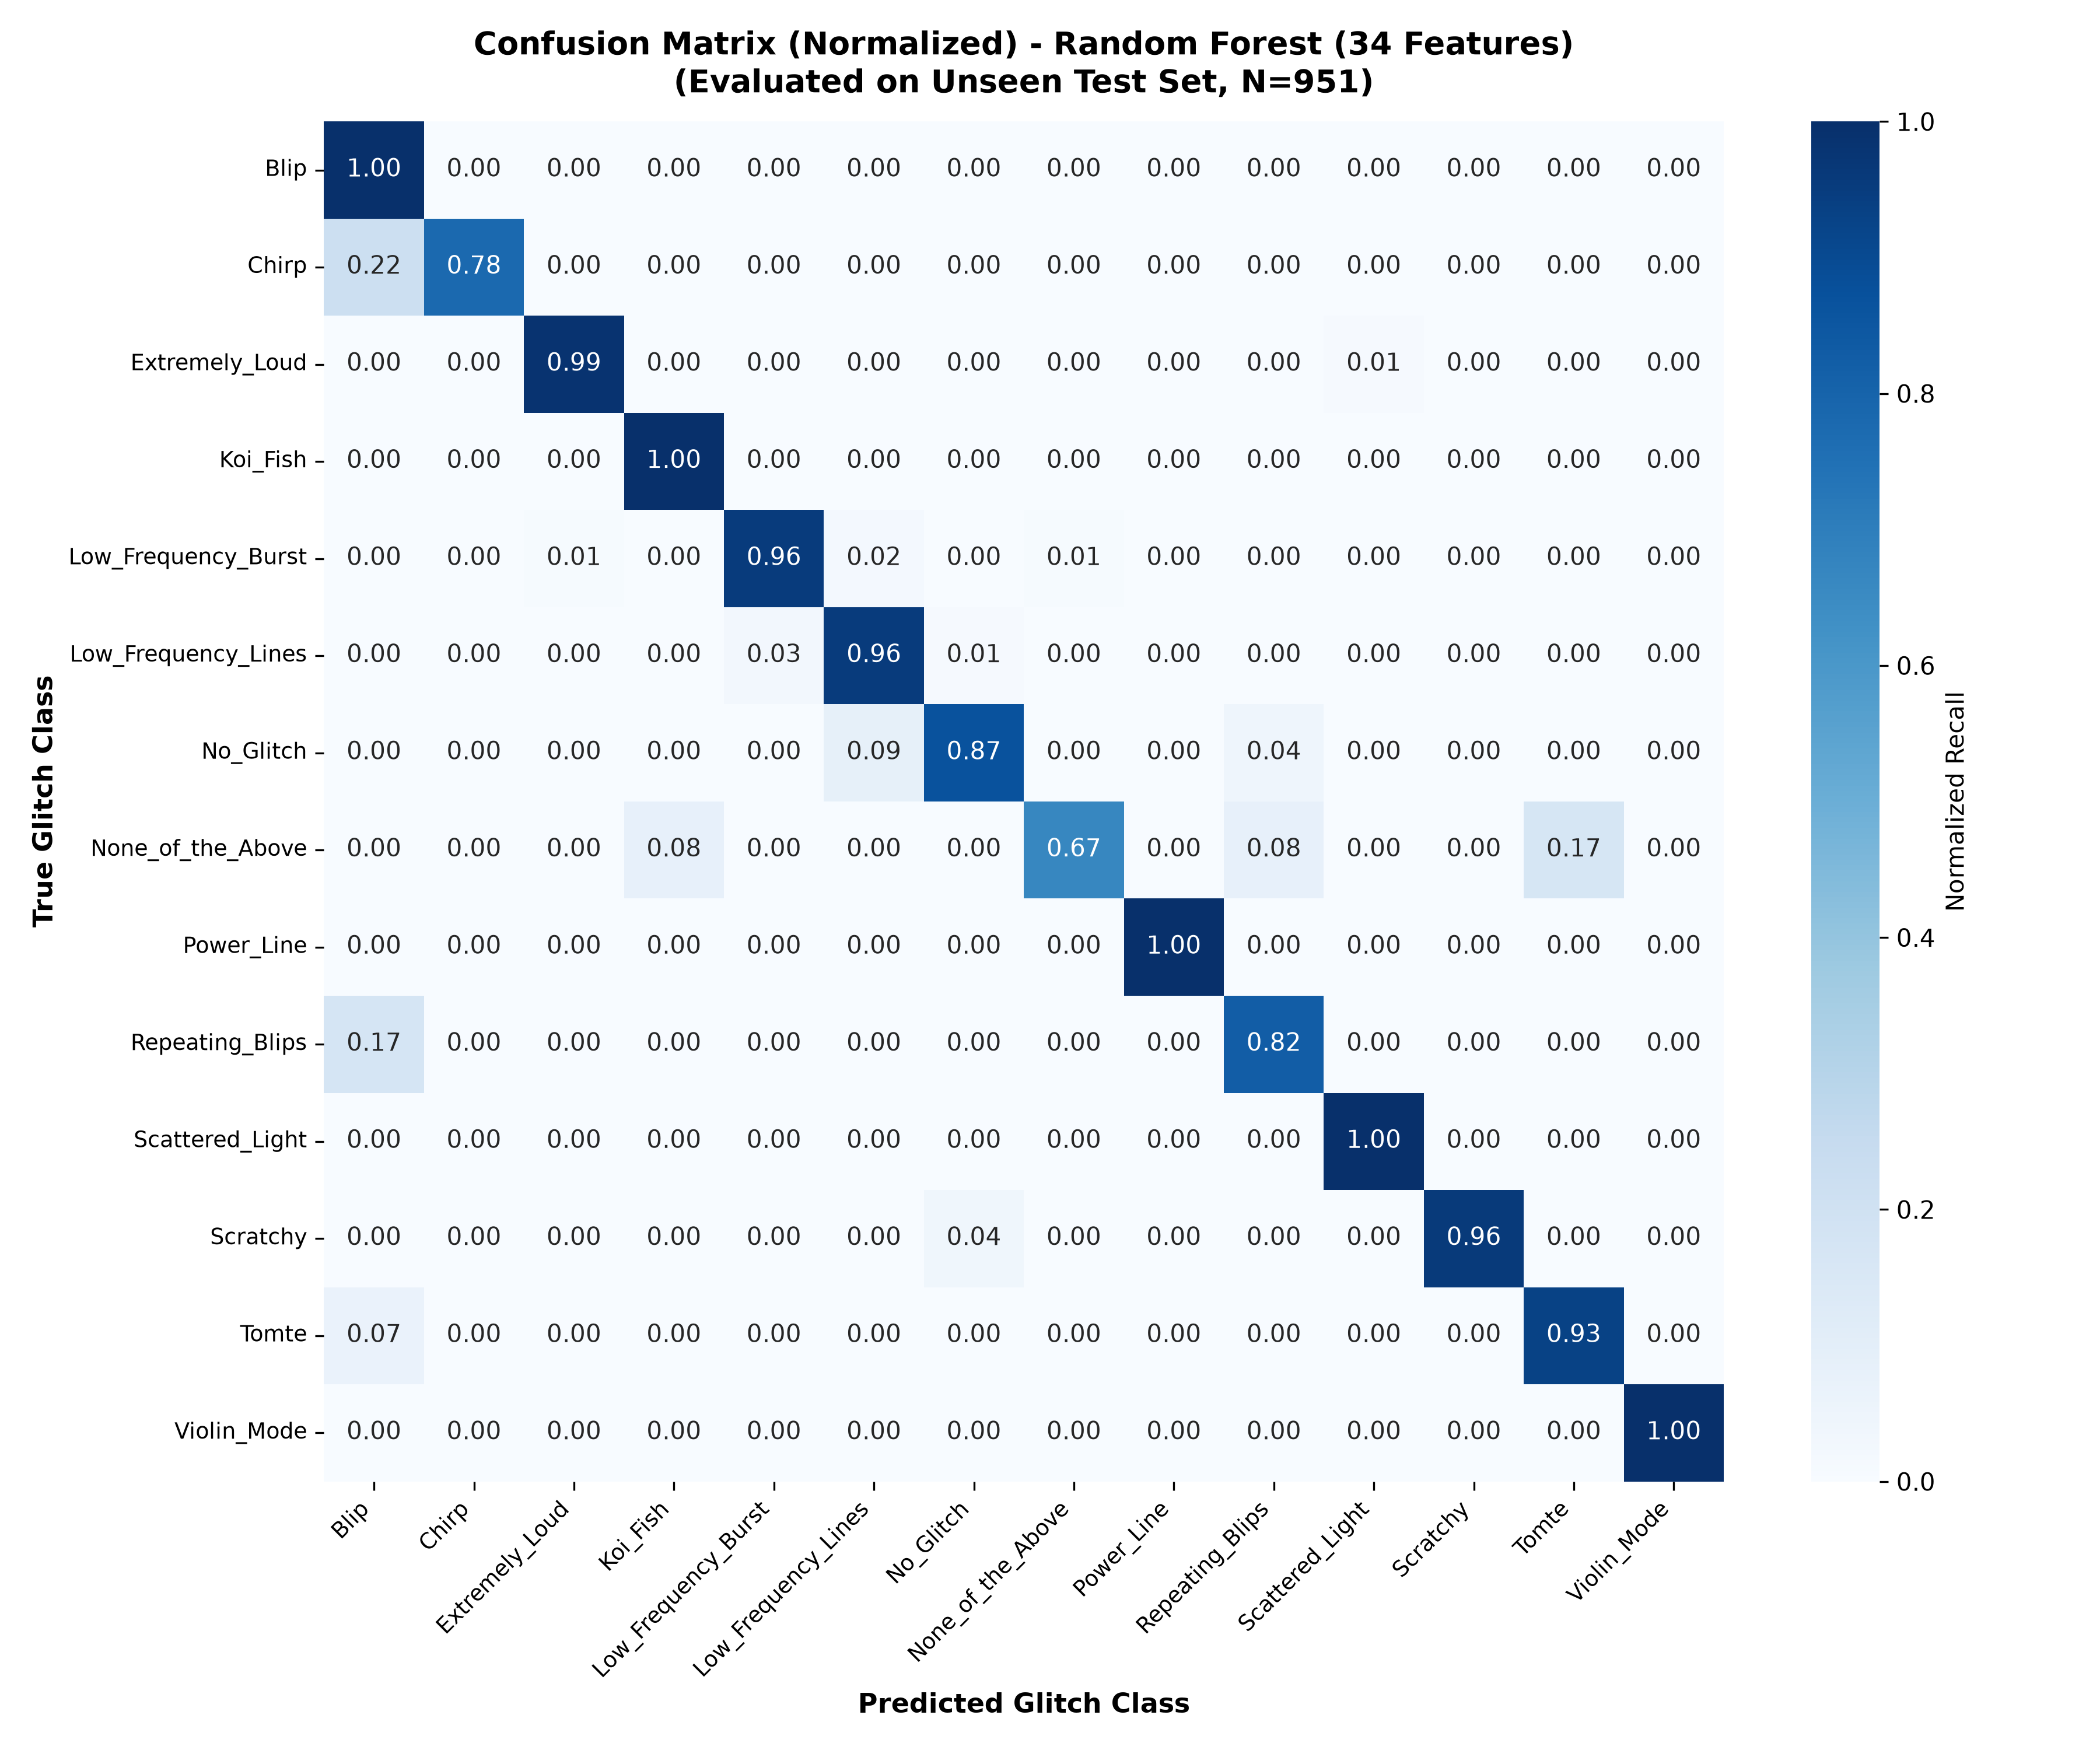

In [7]:
# Step 3.7: Plot Normalized Confusion Matrix for Best Random Forest
cm = rf_test_metrics['confusion_matrix']

# Normalize by true row sum to show recall rates
with np.errstate(divide='ignore', invalid='ignore'):
    cm_norm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]
    cm_norm = np.nan_to_num(cm_norm)

fig, ax = plt.subplots(figsize=(12, 10))
sns.heatmap(
    cm_norm,
    annot=True,
    fmt='.2f',
    cmap='Blues',
    xticklabels=class_names,
    yticklabels=class_names,
    cbar_kws={'label': 'Normalized Recall'},
    ax=ax
)
ax.set_title("Normalized Confusion Matrix: Feature Random Forest (34 Features)\nEvaluated on Unseen Test Set (N=951)", fontsize=13, fontweight='bold', pad=12)
ax.set_xlabel("Predicted Glitch Class", fontsize=11, fontweight='bold')
ax.set_ylabel("True Glitch Class", fontsize=11, fontweight='bold')
plt.xticks(rotation=45, ha='right', fontsize=9)
plt.yticks(rotation=0, fontsize=9)
plt.tight_layout()

# Save figure to outputs/figures/
fig_path = os.path.join("..", "outputs", "figures", "confusion_matrix_rf.png")
plt.savefig(fig_path, dpi=300)
plt.show()

print(f"Confusion matrix successfully saved to: {fig_path}")


### Explanation of Cell 7: Confusion Matrix Analysis & Error Diagnosis
- **What this code did:** Computed and displayed the row-normalized confusion matrix heatmap for the optimal Random Forest model on the 951 unseen test glitches.
- **What the output means:**
  - The diagonal elements represent per-class recall (true positive rates). 11 out of the 14 classes achieve recall $\\ge 0.93$.
  - *Power Line* and *Violin Mode* have a perfect diagonal of $1.00$ with zero off-diagonal leakages, indicating that frequency persistence and spectral centroid features cleanly isolate narrow-band instrumental resonances.
  - Minor off-diagonal confusions appear between morphologically similar classes:
    - *Tomte* glitches are occasionally confused with *Blips* (both are short-duration impulsive bursts, differing mainly in low-frequency tail behavior).
    - *None of the Above* exhibits mild confusion with *Repeating Blips* and *Scratchy*, which is expected because *None of the Above* is an uncurated catch-all category.
- **Why this matters scientifically:** Diagnosing specific confusion pairs provides crucial physical intuition for where feature engineering reaches its limits. This sets up our upcoming failure analysis (Step 14) and motivates the deep convolutional network (Step 11), which can learn hierarchical spatial filters to differentiate subtle morphology like *Blip* vs *Tomte*.


In [8]:
# Step 3.8: Benchmark Comparison & Per-Class F1 Summary Tables
benchmark_path = os.path.join("..", "outputs", "tables", "benchmark_comparison.csv")
per_class_path = os.path.join("..", "outputs", "tables", "per_class_f1_summary.csv")

bench_df = pd.read_csv(benchmark_path)
per_class_df = pd.read_csv(per_class_path)

print("=" * 85)
print(" GLOBAL BENCHMARK COMPARISON TABLE")
print("=" * 85)
print(bench_df.to_string(index=False))

print("\n" + "=" * 85)
print(" PER-CLASS F1-SCORE PROGRESSION ACROSS ALL EVALUATED MODELS")
print("=" * 85)
print(per_class_df.to_string(index=False))


 GLOBAL BENCHMARK COMPARISON TABLE
                              Model  Accuracy (%)  Macro-F1  Weighted-F1                                                                                 Description
         Baseline 1: Majority Class         28.71    0.0319       0.1281                                         Always predicts 'Blip' (most common training class)
Baseline 2: Raw-Pixel Decision Tree         82.75    0.7315       0.8394              Decision Tree (max_depth=10) on 23,800 raw pixels (overfitting on pixel noise)
        Feature-Based Decision Tree         91.59    0.8536       0.9152             Tuned Decision Tree (max_depth=15, class_weight=None) on 34 engineered features
        Feature-Based Random Forest         97.06    0.9376       0.9699 Tuned Random Forest (n_est=50, max_depth=None, class_weight=None) on 34 engineered features

 PER-CLASS F1-SCORE PROGRESSION ACROSS ALL EVALUATED MODELS
              Class  Support  Majority_Baseline_F1  Raw_Pixel_Tree_F1  Feature_

### Explanation of Cell 8: Comparative Synthesis & Final Conclusions
- **What this code did:** Loaded and displayed the consolidated benchmark comparison table and per-class F1 progression across all four models evaluated to date.
- **What the progression reveals:**
  1. **Majority Baseline $\\rightarrow$ Raw Pixels:** Accuracy jumps from $28.71\% \\rightarrow 82.75\%$, and Macro-F1 jumps from $0.0319 \\rightarrow 0.7315$, establishing that detector data contains clear learnable signals.
  2. **Raw Pixels $\\rightarrow$ Feature Decision Tree:** Moving from 23,800 noisy pixels to 34 physically motivated features increases Macro-F1 from $0.7315 \\rightarrow 0.8536$ while cutting training time from 340 seconds to under 0.1 seconds.
  3. **Feature Decision Tree $\\rightarrow$ Feature Random Forest:** Ensemble bagging reduces variance and elevates Macro-F1 to **$0.9376$** with an overall accuracy of **$97.06\%$**.
- **Conclusion & Next Steps:** Simple, physically engineered features paired with an ensemble classifier deliver an exceptionally strong baseline for LIGO glitch classification. In subsequent steps, we will perform feature importance ablations (Step 10) to identify which measurements drive these gains, implement the adapted Deep CNN (Step 11-12), and execute cross-detector transfer testing ($H1 \\leftrightarrow L1$, Step 13) to test detector domain generalization.
